<a href="https://colab.research.google.com/github/Njeon3091/AICE_study/blob/main/Epass_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

In [47]:
#import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 패키지 설치 및 캐시 삭제
!sudo apt-get update -qq
!sudo apt-get install -y fonts-nanum > /dev/null
!rm -rf ~/.cache/matplotlib

# 폰트 매니저에 직접 등록
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
print("폰트 설정 완료")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
폰트 설정 완료


In [48]:
import seaborn as sns

In [49]:
car_df = pd.read_csv("1_used_car_prices.csv")
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         973 non-null    object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [50]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


/tmp/ipykernel_1857/1405527486.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


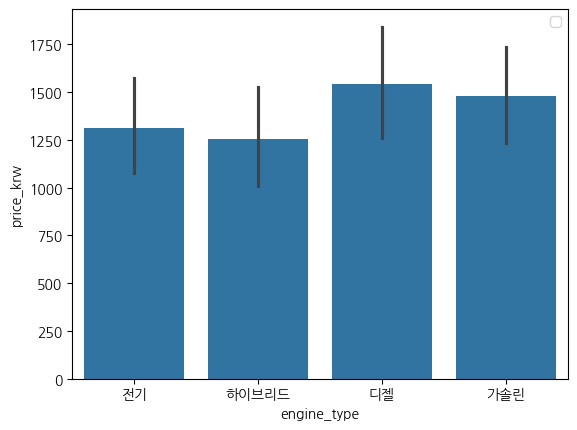

In [51]:
car_df['engine_type'].value_counts()

plt.figure()
sns.barplot(x = car_df['engine_type'], y = car_df['price_krw'])
plt.legend()
plt.show()

In [52]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [53]:
car_df.groupby(['brand', 'option_grade'])['price_krw'].mean()

brand  option_grade
A사     고급              1261.629630
       기본              1188.489583
       중급              1314.852632
B사     고급              1539.666667
       기본              1503.191489
       중급              1877.250000
C사     고급              1165.759259
       기본              1924.813559
       중급              1316.819672
D사     고급              1467.735849
       기본              1218.375000
       중급              1019.464286
Name: price_krw, dtype: float64

In [54]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [55]:
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         973 non-null    object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [56]:
car_pre = car_df.copy()

In [57]:
car_pre['option_grade'].value_counts()

,count
option_grade,
기본,341
고급,332
중급,300


In [58]:
car_pre.columns

Index(['brand', 'age_years', 'mileage_km', 'engine_type', 'engine_size_cc',
       'horsepower', 'fuel_efficiency_kml', 'accident_count', 'color',
       'option_grade', 'price_krw'],
      dtype='object')

In [59]:
mode_df = car_pre['option_grade'].mode()[0]
car_pre['option_grade'].fillna(mode_df, inplace=True)

#car_pre = car_df_na[cols]

/tmp/ipykernel_1857/4224143906.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  car_pre['option_grade'].fillna(mode_df, inplace=True)


In [60]:
mode_df

'기본'

In [61]:
car_pre.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [62]:
car_pre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   color                968 non-null    object 
 9   option_grade         1000 non-null   object 
 10  price_krw            1000 non-null   float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [63]:
car_pre['option_grade'].value_counts()

,count
option_grade,
기본,368
고급,332
중급,300


In [64]:
cols = ['brand', 'age_years', 'mileage_km', 'engine_type', 'engine_size_cc','horsepower', 'fuel_efficiency_kml', 'accident_count','option_grade', 'price_krw']

car_pre = car_pre[cols]

In [65]:
car_pre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                961 non-null    object 
 1   age_years            1000 non-null   float64
 2   mileage_km           1000 non-null   float64
 3   engine_type          979 non-null    object 
 4   engine_size_cc       1000 non-null   float64
 5   horsepower           1000 non-null   float64
 6   fuel_efficiency_kml  1000 non-null   float64
 7   accident_count       1000 non-null   float64
 8   option_grade         1000 non-null   object 
 9   price_krw            1000 non-null   float64
dtypes: float64(7), object(3)
memory usage: 78.3+ KB


In [66]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,NaN,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [67]:
car_df['brand']=car_df['brand'].fillna('unknown')

In [68]:
car_df.head()

,brand,age_years,mileage_km,engine_type,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,option_grade,price_krw
0,B사,14.0,218413.0,전기,3253.0,333.0,8.6,3.0,검정,고급,100.0
1,D사,11.0,90552.0,하이브리드,3294.0,327.0,8.3,0.0,은색,고급,100.0
2,C사,13.0,178150.0,디젤,3805.0,387.0,4.8,0.0,흰색,중급,100.0
3,unknown,7.0,127044.0,하이브리드,1146.0,110.0,19.2,2.0,기타,고급,100.0
4,A사,2.0,40116.0,디젤,3165.0,340.0,8.9,0.0,은색,고급,3987.0


In [69]:
car_numeric = car_df.copy()
car_numeric=pd.get_dummies(car_numeric, columns = ['brand', 'engine_type', 'option_grade'])

In [70]:
car_numeric.head()

,age_years,mileage_km,engine_size_cc,horsepower,fuel_efficiency_kml,accident_count,color,price_krw,brand_A사,brand_B사,brand_C사,brand_D사,brand_unknown,engine_type_가솔린,engine_type_디젤,engine_type_전기,engine_type_하이브리드,option_grade_고급,option_grade_기본,option_grade_중급
0,14.0,218413.0,3253.0,333.0,8.6,3.0,검정,100.0,False,True,False,False,False,False,False,True,False,True,False,False
1,11.0,90552.0,3294.0,327.0,8.3,0.0,은색,100.0,False,False,False,True,False,False,False,False,True,True,False,False
2,13.0,178150.0,3805.0,387.0,4.8,0.0,흰색,100.0,False,False,True,False,False,False,True,False,False,False,False,True
3,7.0,127044.0,1146.0,110.0,19.2,2.0,기타,100.0,False,False,False,False,True,False,False,False,True,True,False,False
4,2.0,40116.0,3165.0,340.0,8.9,0.0,은색,3987.0,True,False,False,False,False,False,True,False,False,True,False,False


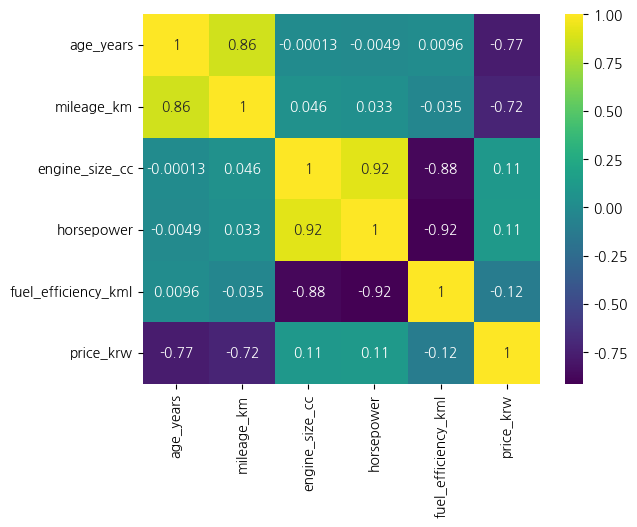

In [71]:
heat_cols=['age_years', 'mileage_km', 'engine_size_cc', 'horsepower', 'fuel_efficiency_kml', 'price_krw']

plt.figure()
sns.heatmap(car_numeric[heat_cols].corr(), annot=True, cmap='viridis')
plt.show()

In [72]:
y = car_numeric['price_krw']
x = car_numeric.drop(['price_krw'], axis=1)

In [73]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age_years            1000 non-null   float64
 1   mileage_km           1000 non-null   float64
 2   engine_size_cc       1000 non-null   float64
 3   horsepower           1000 non-null   float64
 4   fuel_efficiency_kml  1000 non-null   float64
 5   accident_count       1000 non-null   float64
 6   color                968 non-null    object 
 7   brand_A사             1000 non-null   bool   
 8   brand_B사             1000 non-null   bool   
 9   brand_C사             1000 non-null   bool   
 10  brand_D사             1000 non-null   bool   
 11  brand_unknown        1000 non-null   bool   
 12  engine_type_가솔린      1000 non-null   bool   
 13  engine_type_디젤       1000 non-null   bool   
 14  engine_type_전기       1000 non-null   bool   
 15  engine_type_하이브리드    1000 non-null   bo

In [74]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: price_krw
Non-Null Count  Dtype  
--------------  -----  
1000 non-null   float64
dtypes: float64(1)
memory usage: 7.9 KB


In [77]:
from sklearn.model_selection import train_test_split

tts = train_test_split

x_train, y_train, x_test, y_test = tts(x, y, test_size=0.3, random_state = 100)



In [79]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((700, 19), (300, 19), (700,), (300,))